# LightGBM: disrupted airport-days

This notebook fits a LightGBM gradient-boosting classifier that estimates the probability that an airport-day is disrupted, using the same data, predictors, splits and evaluation as the logistic regression in notebook 03. The data (`data/processed/airport_day.parquet`) has one row per airport and day for 12 German airports, 2014–2025. The target `disrupted_day` is 1 if at least 2% of arrivals had more than 15 minutes of ATFM delay; this threshold is a project definition, not an official one. Predictors are the 37 columns approved in the feature contract (calendar, history from earlier days, same-day weather). The data is split by calendar year:

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fit the model |
| select | 2022 | compare settings, early stopping, fit the calibration mappings |
| calibrate | 2023 | choose the calibration method and alert threshold |
| test | 2024–2025 | final evaluation, scored once |

Same-day observed weather is used as if it were a perfect forecast, so this is a retrospective study and the scores are an upper bound for a real day-ahead system. The history columns are assumed to be available at the start of the day; actual EUROCONTROL publication times were not checked. The 2024–2025 period was looked at in earlier project work, so it is a previously inspected test period rather than an untouched one, but it is not used for any decision here.

## 1. Setup

In [1]:
# 1 setup
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import lightgbm as lgb

RANDOM_SEED = 42

# The notebooks live in notebooks/, so the repository root is one level up
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "airport_day.parquet"
CONTRACT_PATH = PROJECT_ROOT / "data" / "processed" / "feature_contract.json"

print("Python:      ", platform.python_version())
print("pandas:      ", pd.__version__)
print("numpy:       ", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("lightgbm:    ", lgb.__version__)
print()
print("Random seed:", RANDOM_SEED)
print("Data file found:    ", DATA_PATH.exists(), "->", DATA_PATH.relative_to(PROJECT_ROOT))
print("Contract file found:", CONTRACT_PATH.exists(), "->", CONTRACT_PATH.relative_to(PROJECT_ROOT))

Python:       3.13.14
pandas:       3.0.3
numpy:        2.4.6
scikit-learn: 1.9.0
lightgbm:     4.6.0

Random seed: 42
Data file found:     True -> data/processed/airport_day.parquet
Contract file found: True -> data/processed/feature_contract.json


Same library versions as notebook 03, plus LightGBM 4.6.0.

## 2. Data checks

The checks in this section are identical to notebook 03.

In [2]:
# 2.1 load the dataset
airport_days = pd.read_parquet(DATA_PATH)

print("Rows:   ", airport_days.shape[0])
print("Columns:", airport_days.shape[1])

Rows:    52596
Columns: 79


Three Frankfurt rows with a subset of columns. `arrivals` is the number of arriving flights, `atfm_delay_min` the total ATFM delay and `arrivals_atfm_delayed_15` the number of arrivals delayed by more than 15 minutes. Dates are UTC.

In [3]:
# 2.2 a few rows for Frankfurt (EDDF), showing only some of the columns
example_columns = [
    "airport_icao", "airport_name", "date", "arrivals", "atfm_delay_min",
    "arrivals_atfm_delayed_15", "temp_mean_c", "gust_max_ms",
    "disrupted_day", "atfm_delay_per_arrival",
]
frankfurt_rows = airport_days[airport_days["airport_icao"] == "EDDF"]
frankfurt_rows[example_columns].head(3)

,airport_icao,airport_name,date,arrivals,atfm_delay_min,arrivals_atfm_delayed_15,temp_mean_c,gust_max_ms,disrupted_day,atfm_delay_per_arrival
1,EDDF,Frankfurt,2014-01-01 00:00:00+00:00,362.0,0.0,0.0,4.575000,8.0,0,0.0
13,EDDF,Frankfurt,2014-01-02 00:00:00+00:00,560.0,1709.0,50.0,7.429167,15.0,1,3.051786
25,EDDF,Frankfurt,2014-01-03 00:00:00+00:00,564.0,1730.0,50.0,7.704167,NaN,1,3.067376


On 2 January 2014, 50 of 560 Frankfurt arrivals (8.9%) were delayed by more than 15 minutes, so the day is disrupted. The `NaN` gust value on 3 January is a real gap in the weather record.

In [4]:
# 2.3 which airports and dates are covered?
coverage = airport_days.groupby(["airport_icao", "airport_name"]).agg(
    rows=("date", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
)
calendar_days = (airport_days["date"].max() - airport_days["date"].min()).days + 1

print("Number of airports:", coverage.shape[0])
print("Calendar days from the first to the last date:", calendar_days)
coverage

Number of airports: 12
Calendar days from the first to the last date: 4383


,,rows,first_date,last_date
airport_icao,airport_name,,,
EDDC,Dresden,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDF,Frankfurt,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDG,Muenster-Osnabrueck,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDH,Hamburg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDK,Cologne-Bonn,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDL,Duesseldorf,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDM,Munich,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDN,Nuremberg,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00
EDDP,Leipzig-Halle,4383,2014-01-01 00:00:00+00:00,2025-12-31 00:00:00+00:00


All 12 airports have 4,383 rows, one for every day from 1 January 2014 to 31 December 2025 (12 × 4,383 = 52,596).

In [5]:
# 2.4 is any airport-date pair listed more than once?
duplicate_count = airport_days.duplicated(subset=["airport_icao", "date"]).sum()
print("Duplicate airport-date rows:", duplicate_count)

Duplicate airport-date rows: 0


The feature contract lists the approved predictors (`predictor_allowlist`) and the same-day outcome columns that must not be used as inputs (`forbidden_same_day_outcomes`).

In [6]:
# 2.5 read the feature contract
import json

with open(CONTRACT_PATH) as contract_file:
    feature_contract = json.load(contract_file)

predictor_columns = feature_contract["predictor_allowlist"]
forbidden_columns = feature_contract["forbidden_same_day_outcomes"]

print("Approved predictors:", len(predictor_columns))
print("Entries in the forbidden list:", len(forbidden_columns), "| unique:", len(set(forbidden_columns)))
print("Contract note:", feature_contract["note"])

Approved predictors: 37
Entries in the forbidden list: 28 | unique: 27
Contract note: Target definition is EUROCONTROL ATFM airport arrival delay (network regulations), not gate/schedule punctuality.


37 approved predictors. The forbidden list has 28 entries but 27 unique names because `atfm_delay_min` appears twice.

In [7]:
# 2.6 data type and missing values for every approved predictor
predictor_overview = pd.DataFrame({
    "dtype": airport_days[predictor_columns].dtypes.astype(str),
    "missing_rows": airport_days[predictor_columns].isna().sum(),
})
predictor_overview["missing_percent"] = (100 * predictor_overview["missing_rows"] / len(airport_days)).round(2)
predictor_overview

,dtype,missing_rows,missing_percent
airport_icao,string,0,0.00
weekday,Int8,0,0.00
month,Int8,0,0.00
doy_sin,float64,0,0.00
doy_cos,float64,0,0.00
is_weekend,bool,0,0.00
is_public_holiday,bool,0,0.00
temp_mean_c,float64,185,0.35
temp_min_c,float64,185,0.35
temp_max_c,float64,185,0.35


- Airport and calendar columns are complete.
- Weather columns are missing on 0.35–1.57% of rows; visibility and the weather-code columns (fog, thunder, snow, freezing) have the most gaps.
- History columns are missing on less than 0.6% of rows, mostly at the start of the series and after gaps.
- Mixed data types are converted to floats in cell 5.3, except the airport code.

In [8]:
# 2.7 does the dataset's own 'split' column agree with the planned years?
pd.crosstab(airport_days["year"], airport_days["split"])

split,calibrate,model_select,test,train
year,,,,
2014,0,0,0,4380
2015,0,0,0,4380
2016,0,0,0,4392
2017,0,0,0,4380
2018,0,0,0,4380
2019,0,0,0,4380
2020,0,0,0,4392
2021,0,0,0,4380
2022,0,4380,0,0


The dataset's `split` column matches the planned years. 2016, 2020 and 2024 have 4,392 rows because they are leap years.

## 3. Target and class balance

Missing labels are counted in all periods; everything else uses the training years only.

In [9]:
# 3.1 rows where the target is missing, and why (counts only)
target_missing = airport_days["disrupted_day"].isna()
print("Rows with missing disrupted_day:", target_missing.sum())

missing_rows = airport_days[target_missing].copy()
missing_rows["reason"] = "other"
missing_rows.loc[~missing_rows["eurocontrol_row_present"], "reason"] = "no EUROCONTROL record for that day"
missing_rows.loc[missing_rows["arrivals"] == 0, "reason"] = "zero arrivals (share cannot be calculated)"
pd.crosstab(missing_rows["reason"], missing_rows["split"])

Rows with missing disrupted_day: 47


split,model_select,test,train
reason,,,
no EUROCONTROL record for that day,8,0,30
zero arrivals (share cannot be calculated),1,1,7


47 rows have no label: 38 have no EUROCONTROL record and 9 have zero arrivals. 37 are in training, 9 in 2022 and 1 in the test years. They are excluded rather than treated as not disrupted.

In [10]:
# 3.2 from here on, explore the training years only (2014-2021)
training_days = airport_days[(airport_days["year"] <= 2021) & ~target_missing].copy()
print("Training rows with a known target:", len(training_days))

# Re-calculate the 2% rule from the raw counts and compare it with the stored label
recalculated_share = training_days["arrivals_atfm_delayed_15"] / training_days["arrivals"]
recalculated_label = (recalculated_share >= 0.02).astype(int)
stored_label = training_days["disrupted_day"].astype(int)
print("Rows where our re-calculation disagrees with disrupted_day:", (recalculated_label != stored_label).sum())

Training rows with a known target: 35027
Rows where our re-calculation disagrees with disrupted_day: 0


Recomputing the 2% rule reproduces `disrupted_day` on all 35,027 labelled training rows.

In [11]:
# 3.3 class balance in the training data
class_counts = training_days["disrupted_day"].value_counts().sort_index()
class_percent = (100 * class_counts / class_counts.sum()).round(2)
pd.DataFrame({"days": class_counts, "percent": class_percent})

,days,percent
disrupted_day,,
0,32976,94.14
1,2051,5.86


2,051 of 35,027 training days (5.86%) are disrupted.

In [12]:
# 3.4 the accuracy of a rule that never predicts a disruption
always_normal_accuracy = (training_days["disrupted_day"] == 0).mean()
print(f"Accuracy of always predicting 'not disrupted': {always_normal_accuracy:.1%}")

Accuracy of always predicting 'not disrupted': 94.1%


A rule that never predicts disruption is 94.1% accurate, so accuracy is not used. Evaluation is based on average precision, precision and recall.

In [13]:
# 3.5 disruption rate by airport (training years)
training_by_airport = training_days.groupby(["airport_icao", "airport_name"]).agg(
    days=("disrupted_day", "size"),
    disrupted_days=("disrupted_day", "sum"),
)
training_by_airport["rate_percent"] = (100 * training_by_airport["disrupted_days"] / training_by_airport["days"]).round(2)
training_by_airport.sort_values("rate_percent", ascending=False)

,,days,disrupted_days,rate_percent
airport_icao,airport_name,,,
EDDF,Frankfurt,2922,506,17.32
EDDL,Duesseldorf,2922,457,15.64
EDDM,Munich,2922,308,10.54
EDDH,Hamburg,2922,267,9.14
EDDK,Cologne-Bonn,2922,210,7.19
EDDP,Leipzig-Halle,2922,104,3.56
EDDW,Bremen,2919,92,3.15
EDDS,Stuttgart,2906,90,3.1
EDDV,Hannover,2922,10,0.34


Disruption rates range from 17.3% (Frankfurt) and 15.6% (Düsseldorf) down to 1 disrupted training day at Münster-Osnabrück (EDDG), 2 at Dresden (EDDC), 4 at Nuremberg (EDDN) and 10 at Hannover (EDDV). At these four airports there is very little to learn from.

In [14]:
# 3.6 disruption rate by year (training years)
training_by_year = training_days.groupby("year").agg(
    days=("disrupted_day", "size"),
    disrupted_days=("disrupted_day", "sum"),
)
training_by_year["rate_percent"] = (100 * training_by_year["disrupted_days"] / training_by_year["days"]).round(2)
training_by_year

,days,disrupted_days,rate_percent
year,,,
2014,4380,251,5.73
2015,4380,230,5.25
2016,4392,271,6.17
2017,4380,340,7.76
2018,4380,408,9.32
2019,4380,381,8.7
2020,4358,37,0.85
2021,4377,133,3.04


The rate rose from 5.7% (2014) to 9.3% (2018), then fell to 0.85% in 2020 and 3.0% in 2021 because of COVID. These two years are a quarter of the training data, and the model has no COVID input; it can only pick up the lower traffic through the arrival-history columns. The planned full training period is kept.

## 4. Predictors

Same-day outcomes such as `share_arrivals_delayed_15`, `atfm_delay_min` and `atfm_delay_per_arrival` are only known after the day and are excluded to avoid leakage. Lagged and rolling history columns computed from earlier days are allowed.

In [15]:
# 4.1 group the approved predictors by when their information is available
predictor_info = pd.DataFrame(feature_contract["predictors"])
predictor_info = predictor_info[predictor_info["name"].isin(predictor_columns)]
print("Approved predictors described in the contract:", len(predictor_info))
print()

for availability, group in predictor_info.groupby("availability_assumption"):
    print(f"{availability}  ({len(group)} columns)")
    print("   ", ", ".join(group["name"]))
    print()

Approved predictors described in the contract: 37

Computed from days strictly before the row's day (known at the start of the day)  (10 columns)
    arrivals_lag1, arrivals_lag7, arrivals_mean_7d, delay_per_arrival_lag1, share_delayed15_lag1, disrupted_lag1, delay_per_arrival_mean_7d, delay_per_arrival_mean_28d, disrupted_rate_28d, weather_delay_per_arrival_mean_28d

Known in advance  (7 columns)
    airport_icao, weekday, month, doy_sin, doy_cos, is_weekend, is_public_holiday

Same-day OBSERVED weather standing in for a day-ahead forecast (perfect-forecast assumption; scores are an upper bound)  (20 columns)
    temp_mean_c, temp_min_c, temp_max_c, frost_day, rh_mean_pct, wind_mean_ms, wind_max_ms, gust_max_ms, gust_hours_ge15, precip_sum_mm, precip_max_1h_mm, precip_hours, cold_precip_hours, vis_min_m, low_vis_hours_lt1000, vis_hours_lt5000, fog_hours, thunder_hours, snow_hours, freezing_hours



7 predictors are known in advance (airport, calendar), 10 are history computed from earlier days, and 20 are same-day observed weather, to which the perfect-forecast assumption applies.

In [16]:
# 4.2 make sure no forbidden column or the target slipped into the predictor list
overlap = set(predictor_columns) & set(forbidden_columns)
print("Predictors that are also forbidden outcomes:", sorted(overlap))
print("Is disrupted_day in the predictor list?", "disrupted_day" in predictor_columns)

unused_columns = []
for column in airport_days.columns:
    if column not in predictor_columns:
        unused_columns.append(column)
print()
print(len(unused_columns), "columns are NOT used as predictors:")
print(", ".join(unused_columns))

Predictors that are also forbidden outcomes: []
Is disrupted_day in the predictor list? False

42 columns are NOT used as predictors:
date, airport_name, dwd_station, arrivals, atfm_delay_min, arrivals_atfm_delayed, arrivals_atfm_delayed_15, atfm_version, delay_accident_min, delay_atc_capacity_min, delay_deicing_min, delay_equipment_non_atc_min, delay_aerodrome_capacity_min, delay_atc_industrial_min, delay_airspace_mgmt_min, delay_industrial_non_atc_min, delay_other_min, delay_special_event_min, delay_atc_routeing_min, delay_atc_staffing_min, delay_equipment_atc_min, delay_environment_min, delay_weather_min, delay_not_specified_min, delay_blank_in_source, eurocontrol_row_present, temp_valid_hours, wind_valid_hours, gust_valid_hours, precip_valid_hours, vis_valid_hours, ww_reported_hours, atfm_delay_per_arrival, share_arrivals_delayed_15, weather_delay_per_arrival, disrupted_day, severe_disrupted_day, any_atfm_delay_day, weather_atfm_day, year, covid_traffic_period, split


No approved predictor is on the forbidden list and the target is not included. The 42 unused columns are identifiers, same-day outcomes (including today's `arrivals`), data-quality fields and the COVID flag `covid_traffic_period`.

In [17]:
# 4.3 a lag column is yesterday's value moved forward by one day (Frankfurt, a week in July 2019)
lag_example = airport_days[
    (airport_days["airport_icao"] == "EDDF")
    & (airport_days["date"] >= pd.Timestamp("2019-07-01", tz="UTC"))
    & (airport_days["date"] <= pd.Timestamp("2019-07-05", tz="UTC"))
]
lag_example[["date", "atfm_delay_per_arrival", "delay_per_arrival_lag1", "disrupted_day", "disrupted_lag1"]]

,date,atfm_delay_per_arrival,delay_per_arrival_lag1,disrupted_day,disrupted_lag1
24085,2019-07-01 00:00:00+00:00,0.946309,0.000000,1,0.0
24097,2019-07-02 00:00:00+00:00,0.0,0.946309,0,1.0
24109,2019-07-03 00:00:00+00:00,0.0,0.000000,0,0.0
24121,2019-07-04 00:00:00+00:00,0.0,0.000000,0,0.0
24133,2019-07-05 00:00:00+00:00,0.0,0.000000,0,0.0


Frankfurt, 1 July 2019: 0.946 min ATFM delay per arrival and disrupted. On 2 July, `delay_per_arrival_lag1 = 0.946` and `disrupted_lag1 = 1`, i.e. the lag columns contain the previous day's values only.

## 5. Time-based split

Splitting by calendar year keeps neighbouring, highly similar days in the same period and evaluates each period on days after the training data. All airports on a given date fall in the same period.

| Period | Years | Use |
|---|---|---|
| train | 2014–2021 | fit the model |
| select | 2022 | compare settings, early stopping, fit the calibration mappings |
| calibrate | 2023 | choose the calibration method and alert threshold |
| test | 2024–2025 | final evaluation, scored once |

The 47 unlabelled rows are dropped. The 2024–2025 disruption rate is not printed until section 11.

In [18]:
# 5.1 one table per period, keeping only rows with a known target
has_target = airport_days["disrupted_day"].notna()

train_days = airport_days[(airport_days["year"] <= 2021) & has_target].copy()
select_days = airport_days[(airport_days["year"] == 2022) & has_target].copy()
calibrate_days = airport_days[(airport_days["year"] == 2023) & has_target].copy()
test_days = airport_days[(airport_days["year"] >= 2024) & has_target].copy()

period_tables = {
    "train 2014-2021": train_days,
    "select 2022": select_days,
    "calibrate 2023": calibrate_days,
    "test 2024-2025": test_days,
}

summary_rows = []
for period_name, table in period_tables.items():
    summary_rows.append({
        "period": period_name,
        "rows": len(table),
        "first_date": table["date"].min().date(),
        "last_date": table["date"].max().date(),
    })
print("Rows dropped because the target is missing:", (~has_target).sum())
pd.DataFrame(summary_rows)

Rows dropped because the target is missing: 47


,period,rows,first_date,last_date
0,train 2014-2021,35027,2014-01-01,2021-12-31
1,select 2022,4371,2022-01-01,2022-12-31
2,calibrate 2023,4380,2023-01-01,2023-12-31
3,test 2024-2025,8771,2024-01-01,2025-12-31


35,027 training rows, 4,371 for 2022, 4,380 for 2023 and 8,771 for 2024–2025.

In [19]:
# 5.2 disruption rate in the pre-test periods, and a check that no date is in two periods
for period_name in ["train 2014-2021", "select 2022", "calibrate 2023"]:
    rate = period_tables[period_name]["disrupted_day"].mean()
    print(f"{period_name}: {rate:.1%} disrupted days")
print("test 2024-2025: not inspected until section 11")

date_and_period = []
for period_name, table in period_tables.items():
    date_and_period.append(pd.DataFrame({"date": table["date"], "period": period_name}))
date_and_period = pd.concat(date_and_period)
periods_per_date = date_and_period.groupby("date")["period"].nunique()
print()
print("Largest number of periods any single date appears in:", periods_per_date.max())

train 2014-2021: 5.9% disrupted days
select 2022: 6.9% disrupted days
calibrate 2023: 8.3% disrupted days
test 2024-2025: not inspected until section 11

Largest number of periods any single date appears in: 1


Disruption rates: 5.9% in training, 6.9% in 2022 and 8.3% in 2023. Each date belongs to exactly one period.

Boolean and integer columns are converted to floats and missing values are kept as `NaN`, which LightGBM handles natively. The airport code becomes a pandas category with the fixed list of the 12 training airports, so each airport has the same internal code in every period.

In [20]:
# 5.3 build the model inputs (X) and the target (y) for each period
airport_categories = sorted(train_days["airport_icao"].unique())


def make_model_inputs(table):
    features = table[predictor_columns].copy()
    for column in predictor_columns:
        if column == "airport_icao":
            # same fixed category list for every period
            features[column] = pd.Categorical(features[column].astype(str), categories=airport_categories)
        else:
            # True/False and whole-number columns become ordinary decimal numbers; missing stays NaN
            features[column] = features[column].astype("float64")
    target = table["disrupted_day"].astype(int)
    return features, target


X_train, y_train = make_model_inputs(train_days)
X_select, y_select = make_model_inputs(select_days)
X_calibrate, y_calibrate = make_model_inputs(calibrate_days)
X_test, y_test = make_model_inputs(test_days)

print("X_train:    ", X_train.shape)
print("X_select:   ", X_select.shape)
print("X_calibrate:", X_calibrate.shape)
print("X_test:     ", X_test.shape)

X_train:     (35027, 37)
X_select:    (4371, 37)
X_calibrate: (4380, 37)
X_test:      (8771, 37)


## 6. Benchmarks

Same benchmarks and metrics as notebook 03: a constant training rate and the airport's previous 28-day disruption rate, scored with average precision (main metric, fixed in advance), ROC-AUC and the Brier score.

In [21]:
# 6.1 one small helper that scores predicted probabilities
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score


def probability_scores(y_true, predicted_probability):
    return {
        "average_precision": average_precision_score(y_true, predicted_probability),
        "roc_auc": roc_auc_score(y_true, predicted_probability),
        "brier_score": brier_score_loss(y_true, predicted_probability),
    }

In [22]:
# 6.2 the two benchmark rules
training_disruption_rate = y_train.mean()
print(f"Training disruption rate (constant benchmark and fill value): {training_disruption_rate:.4f}")


def rolling_rate_benchmark(table):
    rate = table["disrupted_rate_28d"].astype("float64")
    return rate.fillna(training_disruption_rate).to_numpy()


print()
print("Rows with no 28-day history (filled with the training rate):")
for period_name, table in period_tables.items():
    print(f"  {period_name}: {table['disrupted_rate_28d'].isna().sum()}")

Training disruption rate (constant benchmark and fill value): 0.0586

Rows with no 28-day history (filled with the training rate):
  train 2014-2021: 260
  select 2022: 14
  calibrate 2023: 0
  test 2024-2025: 0


The training rate is 0.0586. The 28-day rate is missing for 260 training rows and 14 rows in 2022 and is filled with the training rate.

In [23]:
# 6.3 benchmark scores on the two pre-test periods
benchmark_rows = []
for period_name, table, y_true in [("select 2022", select_days, y_select), ("calibrate 2023", calibrate_days, y_calibrate)]:
    constant_probability = np.full(len(y_true), training_disruption_rate)
    rolling_probability = rolling_rate_benchmark(table)

    row = {"period": period_name, "benchmark": "constant training rate"}
    row.update(probability_scores(y_true, constant_probability))
    benchmark_rows.append(row)

    row = {"period": period_name, "benchmark": "previous 28-day rate"}
    row.update(probability_scores(y_true, rolling_probability))
    benchmark_rows.append(row)

benchmark_results = pd.DataFrame(benchmark_rows)
benchmark_results.round(4)

,period,benchmark,average_precision,roc_auc,brier_score
0,select 2022,constant training rate,0.0691,0.5000,0.0644
1,select 2022,previous 28-day rate,0.3478,0.8514,0.0520
2,calibrate 2023,constant training rate,0.0831,0.5000,0.0768
3,calibrate 2023,previous 28-day rate,0.3294,0.8592,0.0633


The constant rule has AP equal to the disruption rate (0.069 and 0.083) and ROC-AUC 0.5. The 28-day rule reaches AP 0.35 (2022) and 0.33 (2023) with ROC-AUC about 0.85.

## 7. Preprocessing

Tree splits depend only on the order of values, so no scaling is applied. Missing values are left in place: at each split LightGBM learns which branch they go to, which means that missingness itself can become a signal (reflecting station gaps, not weather). The airport is used as a categorical feature, so the category list must be identical at training and prediction time.

In [24]:
# 7.1 rescaling does not change which days fall on each side of a tree split
gust_ms = X_train["gust_max_ms"]
gust_kmh = gust_ms * 3.6
same_groups = ((gust_ms > 20) == (gust_kmh > 20 * 3.6)).all()
print("Same days on each side of 'gust > 20 m/s' and 'gust > 72 km/h':", same_groups)

# the trees see the raw units
X_train[["temp_mean_c", "gust_max_ms", "arrivals_lag1"]].describe().round(2)

Same days on each side of 'gust > 20 m/s' and 'gust > 72 km/h': True


,temp_mean_c,gust_max_ms,arrivals_lag1
count,35025.00,34895.00,35000.00
mean,10.79,10.44,173.81
std,7.05,4.05,188.53
min,-13.30,2.00,0.00
25%,5.32,7.50,40.00
50%,10.60,9.80,99.00
75%,16.32,12.70,219.00
max,32.05,40.00,806.00


Splitting gusts at 20 m/s and at 72 km/h puts the same days on each side, so rescaling has no effect.

In [25]:
# 7.2 missing values that LightGBM will handle by itself
missing_per_column = X_train.isna().sum()
print("Missing cells in the training inputs:", missing_per_column.sum())
print("Training rows with at least one missing predictor:", X_train.isna().any(axis=1).sum(), "of", len(X_train))
missing_per_column[missing_per_column > 0].sort_values(ascending=False).head(10)

Missing cells in the training inputs: 2026
Training rows with at least one missing predictor: 508 of 35027


weather_delay_per_arrival_mean_28d    260
disrupted_rate_28d                    260
delay_per_arrival_mean_28d            260
gust_max_ms                           132
gust_hours_ge15                       132
wind_mean_ms                          118
wind_max_ms                           118
arrivals_lag7                         103
precip_max_1h_mm                       92
precip_hours                           92
dtype: int64

The training inputs have 2,026 missing cells in 508 of 35,027 rows (1.5%). Missing visibility and weather-code values are rare in training (1 row) but common in 2022 and 2023 (about 330–350 rows per year), so the learned direction for missing values in those columns rests on almost no training examples. The logistic regression has the same weakness in a different form (median imputation).

In [26]:
# 7.3 the airport category mapping, and a check that every period uses the same one
for category_code, airport in enumerate(airport_categories):
    print(category_code, airport)

print()
for period_name, X in [("select 2022", X_select), ("calibrate 2023", X_calibrate), ("test 2024-2025", X_test)]:
    same_categories = list(X["airport_icao"].cat.categories) == airport_categories
    print(f"{period_name}: same airport categories as training -> {same_categories}")

0 EDDC
1 EDDF
2 EDDG
3 EDDH
4 EDDK
5 EDDL
6 EDDM
7 EDDN
8 EDDP
9 EDDS
10 EDDV
11 EDDW

select 2022: same airport categories as training -> True
calibrate 2023: same airport categories as training -> True
test 2024-2025: same airport categories as training -> True


All three later periods use the same airport category list as training (codes 0 = EDDC to 11 = EDDW).

In [27]:
# 7.4 final check of what goes into the model
print("Input columns:", X_train.shape[1])
X_train.dtypes.astype(str).value_counts()

Input columns: 37


float64     36
category     1
Name: count, dtype: int64

36 numeric columns and 1 categorical column, the same 37 predictors as notebook 03.

## 8. First model

LightGBM with learning rate 0.05, `num_leaves = 31`, `min_child_samples = 20`, up to 2,000 trees and early stopping on 2022 AP after 100 rounds without improvement. `deterministic=True` and the fixed seed make the result reproducible. Because 2022 also determines the stopping point, the 2022 score is slightly optimistic.

In [28]:
# 8.1 fit a first LightGBM classifier on 2014-2021, with early stopping on 2022
first_model = lgb.LGBMClassifier(
    n_estimators=2000,
    learning_rate=0.05,
    num_leaves=31,
    min_child_samples=20,
    metric="average_precision",
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
first_model.fit(
    X_train,
    y_train,
    eval_set=[(X_select, y_select)],
    callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
)
print("Trees kept after early stopping:", first_model.best_iteration_)

first_select_probability = first_model.predict_proba(X_select)[:, 1]
first_model_scores = probability_scores(y_select, first_select_probability)
for metric_name, value in first_model_scores.items():
    print(f"{metric_name}: {value:.4f}")

Trees kept after early stopping: 35
average_precision: 0.4788
roc_auc: 0.8915
brier_score: 0.0486


Early stopping kept 35 trees. The model reaches AP 0.479 on 2022 (logistic regression: 0.465), ROC-AUC 0.892 and Brier 0.049.

In [29]:
# 8.2 are the predicted probabilities roughly the right size?
print(f"Average predicted probability in 2022: {first_select_probability.mean():.4f}")
print(f"Actual disruption rate in 2022:        {y_select.mean():.4f}")
print(f"Training disruption rate (2014-2021):  {training_disruption_rate:.4f}")

Average predicted probability in 2022: 0.0603
Actual disruption rate in 2022:        0.0691
Training disruption rate (2014-2021):  0.0586


The mean predicted probability for 2022 is 6.0% against an observed 6.9%, still low but much closer than the 4.4% of the logistic regression.

## 9. Tuning

Eight combinations are compared: `num_leaves` ∈ {7, 15, 31, 63} and `min_child_samples` ∈ {20, 100}, all with learning rate 0.05 and their own early-stopped number of trees. Selection rule, fixed in advance: highest AP on 2022. Class weights were not tested, to keep the probabilities interpretable. As a robustness check only, each combination is refitted on 2014–2022 with its chosen number of trees and scored on 2023 (cell 9.3).

In [30]:
# 9.1 try 8 tree settings, train on 2014-2021, early stopping and scoring on 2022
leaf_options = [7, 15, 31, 63]
min_child_options = [20, 100]

tuning_rows = []
for num_leaves in leaf_options:
    for min_child_samples in min_child_options:
        candidate = lgb.LGBMClassifier(
            n_estimators=2000,
            learning_rate=0.05,
            num_leaves=num_leaves,
            min_child_samples=min_child_samples,
            metric="average_precision",
            random_state=RANDOM_SEED,
            deterministic=True,
            force_col_wise=True,
            verbose=-1,
        )
        candidate.fit(
            X_train,
            y_train,
            eval_set=[(X_select, y_select)],
            callbacks=[lgb.early_stopping(stopping_rounds=100, verbose=False)],
        )
        select_probability = candidate.predict_proba(X_select)[:, 1]

        row = {"num_leaves": num_leaves, "min_child_samples": min_child_samples, "trees": candidate.best_iteration_}
        row.update(probability_scores(y_select, select_probability))
        tuning_rows.append(row)

tuning_results = pd.DataFrame(tuning_rows)
tuning_results.round(4)

,num_leaves,min_child_samples,trees,average_precision,roc_auc,brier_score
0,7,20,94,0.4501,0.8851,0.0483
1,7,100,107,0.4605,0.8858,0.0478
2,15,20,43,0.4775,0.8912,0.0481
3,15,100,42,0.4839,0.8903,0.0480
4,31,20,35,0.4788,0.8915,0.0486
5,31,100,35,0.4919,0.8903,0.0476
6,63,20,52,0.4780,0.8907,0.0475
7,63,100,39,0.4949,0.8920,0.0472


2022 AP ranges from 0.450 (7 leaves, 20) to 0.495 (63 leaves, 100). `min_child_samples = 100` is better than 20 at every leaf size. Early stopping kept between 35 and 107 trees, with the smallest trees needing the most.

In [31]:
# 9.2 apply the selection rule (highest 2022 average precision)
best_row = tuning_results.loc[tuning_results["average_precision"].idxmax()]
best_num_leaves = int(best_row["num_leaves"])
best_min_child_samples = int(best_row["min_child_samples"])
best_trees = int(best_row["trees"])
print("Chosen num_leaves:       ", best_num_leaves)
print("Chosen min_child_samples:", best_min_child_samples)
print("Number of trees:         ", best_trees)
print(f"2022 average precision:   {best_row['average_precision']:.4f}")

Chosen num_leaves:        63
Chosen min_child_samples: 100
Number of trees:          39
2022 average precision:   0.4949


Selected: 63 leaves, `min_child_samples = 100`, 39 trees, 2022 AP 0.4949.

In [32]:
# 9.3 robustness check only - refit on 2014-2022 (same number of trees) and score on 2023
X_train_and_select = pd.concat([X_train, X_select])
y_train_and_select = pd.concat([y_train, y_select])

check_rows = []
for index, setting in tuning_results.iterrows():
    candidate = lgb.LGBMClassifier(
        n_estimators=int(setting["trees"]),
        learning_rate=0.05,
        num_leaves=int(setting["num_leaves"]),
        min_child_samples=int(setting["min_child_samples"]),
        random_state=RANDOM_SEED,
        deterministic=True,
        force_col_wise=True,
        verbose=-1,
    )
    candidate.fit(X_train_and_select, y_train_and_select)
    check_probability = candidate.predict_proba(X_calibrate)[:, 1]
    check_rows.append({
        "num_leaves": int(setting["num_leaves"]),
        "min_child_samples": int(setting["min_child_samples"]),
        "AP_2022 (train 2014-2021)": setting["average_precision"],
        "AP_2023 (train 2014-2022)": average_precision_score(y_calibrate, check_probability),
    })

pd.DataFrame(check_rows).round(4)

,num_leaves,min_child_samples,AP_2022 (train 2014-2021),AP_2023 (train 2014-2022)
0,7,20,0.4501,0.4916
1,7,100,0.4605,0.4910
2,15,20,0.4775,0.4977
3,15,100,0.4839,0.4879
4,31,20,0.4788,0.5027
5,31,100,0.4919,0.5115
6,63,20,0.4780,0.5042
7,63,100,0.4949,0.5075


The 2023 check does not reproduce the 2022 ranking. The best setting on 2023 is 31 leaves / 100 (0.5115), with the chosen 63 / 100 second (0.5075), and the 7-leaf settings are within about 0.02 on 2023 although clearly behind on 2022. Differences between settings (about 0.02) are of the same size as year-to-year variation, so the exact winner is uncertain. The 2022 choice is kept as specified.

The model is now frozen: the selected settings and 39 trees, refitted on 2014–2021 without early stopping. Later sections only add a separate calibration mapping.

In [33]:
# 9.4 the frozen model - chosen settings and number of trees, trained on 2014-2021
final_model = lgb.LGBMClassifier(
    n_estimators=best_trees,
    learning_rate=0.05,
    num_leaves=best_num_leaves,
    min_child_samples=best_min_child_samples,
    random_state=RANDOM_SEED,
    deterministic=True,
    force_col_wise=True,
    verbose=-1,
)
final_model.fit(X_train, y_train)

final_select_probability = final_model.predict_proba(X_select)[:, 1]
print(f"Frozen model, 2022 average precision: {average_precision_score(y_select, final_select_probability):.4f}")

Frozen model, 2022 average precision: 0.4949


## 10. Calibration and alert threshold

As in notebook 03: no calibration, sigmoid and isotonic are fitted on the 2022 predictions and compared on 2023, and the option with the lowest 2023 Brier score is selected.

In [34]:
# 10.1 fit sigmoid and isotonic calibration on 2022 (the model itself stays frozen)
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

sigmoid_calibrated = CalibratedClassifierCV(FrozenEstimator(final_model), method="sigmoid")
sigmoid_calibrated.fit(X_select, y_select)

isotonic_calibrated = CalibratedClassifierCV(FrozenEstimator(final_model), method="isotonic")
isotonic_calibrated.fit(X_select, y_select)
print("Calibration mappings fitted on", len(y_select), "days from 2022")

Calibration mappings fitted on 4371 days from 2022


In [35]:
# 10.2 compare the three options on 2023
calibration_options = {
    "none": final_model,
    "sigmoid": sigmoid_calibrated,
    "isotonic": isotonic_calibrated,
}

calibration_rows = []
calibrate_probabilities = {}
for option_name, option_model in calibration_options.items():
    probability = option_model.predict_proba(X_calibrate)[:, 1]
    calibrate_probabilities[option_name] = probability

    row = {"calibration": option_name}
    row.update(probability_scores(y_calibrate, probability))
    row["mean_probability"] = probability.mean()
    row["distinct_probability_values"] = len(np.unique(probability))
    calibration_rows.append(row)

calibration_results = pd.DataFrame(calibration_rows)
chosen_calibration = calibration_results.loc[calibration_results["brier_score"].idxmin(), "calibration"]
chosen_model = calibration_options[chosen_calibration]

print(f"Actual disruption rate in 2023: {y_calibrate.mean():.4f}")
print("Chosen calibration (lowest 2023 Brier score):", chosen_calibration)
calibration_results.round(4)

Actual disruption rate in 2023: 0.0831
Chosen calibration (lowest 2023 Brier score): isotonic


,calibration,average_precision,roc_auc,brier_score,mean_probability,distinct_probability_values
0,none,0.4673,0.9033,0.0577,0.0663,2427
1,sigmoid,0.4673,0.9033,0.0592,0.0740,2427
2,isotonic,0.4384,0.9016,0.0571,0.0763,48


- No calibration: Brier 0.0577, mean probability 6.6% (observed 8.3%).
- Sigmoid: Brier 0.0592, worse than no calibration.
- Isotonic: Brier 0.0571, but only 48 distinct values, which lowers AP from 0.467 to 0.438.

Under the pre-specified rule isotonic is selected, by a margin of 0.0006 in Brier score. This trades some 2023 ranking quality for slightly better probabilities; a different reasonable rule would have chosen no calibration.

Reliability plot on 2023 with up to 10 quantile groups of days; ties in the LightGBM probabilities leave 8 groups of unequal size.

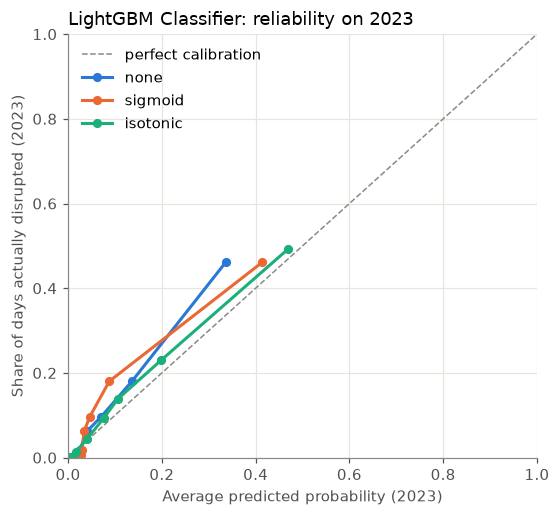

In [36]:
import matplotlib.pyplot as plt

# One consistent, quiet style for every plot in this notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
MODEL_COLOR = "#2a78d6"      # blue: the model
SECOND_COLOR = "#eb6834"     # orange: second line (benchmark or alternative)
THIRD_COLOR = "#1baf7a"      # green: third line
REFERENCE_COLOR = "#8a8984"  # grey: reference lines

from sklearn.calibration import calibration_curve

option_colors = {"none": MODEL_COLOR, "sigmoid": SECOND_COLOR, "isotonic": THIRD_COLOR}

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color=REFERENCE_COLOR, linewidth=1, label="perfect calibration")
for option_name, probability in calibrate_probabilities.items():
    actual_share, mean_predicted = calibration_curve(y_calibrate, probability, n_bins=10, strategy="quantile")
    ax.plot(mean_predicted, actual_share, marker="o", markersize=5, linewidth=2,
            color=option_colors[option_name], label=option_name)
ax.set_xlabel("Average predicted probability (2023)")
ax.set_ylabel("Share of days actually disrupted (2023)")
ax.set_title(f"LightGBM Classifier: reliability on 2023", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend(frameon=False)
plt.show()

Without calibration the highest-risk group (mean prediction about 34%) was disrupted about 46% of the time, so the model is too low at the top end. The isotonic curve follows the diagonal most closely. Small deviations are not meaningful with only a few hundred days per point.

The alert threshold is the one with the highest F1 on 2023 (searched from 0.01 to 0.90 in steps of 0.01). F1 weights both error types roughly equally, which is a convenience choice, not based on operational costs. 2023 scores in this section are selection scores.

In [37]:
# 10.4 what different thresholds would mean on 2023
from sklearn.metrics import f1_score, precision_score, recall_score


def threshold_scores(y_true, probability, threshold):
    alerts = (probability >= threshold).astype(int)
    return {
        "threshold": threshold,
        "alerts": int(alerts.sum()),
        "precision": precision_score(y_true, alerts, zero_division=0),
        "recall": recall_score(y_true, alerts, zero_division=0),
        "f1": f1_score(y_true, alerts, zero_division=0),
    }


calibrate_probability = calibrate_probabilities[chosen_calibration]
print("Disrupted days in 2023:", int(y_calibrate.sum()))

example_rows = []
for threshold in [0.05, 0.10, 0.20, 0.30, 0.50]:
    example_rows.append(threshold_scores(y_calibrate, calibrate_probability, threshold))
pd.DataFrame(example_rows).round(3)

Disrupted days in 2023: 364


,threshold,alerts,precision,recall,f1
0,0.05,1389,0.238,0.909,0.378
1,0.10,901,0.316,0.783,0.451
2,0.20,497,0.431,0.588,0.497
3,0.30,350,0.486,0.467,0.476
4,0.50,91,0.604,0.151,0.242


On 2023 (364 disrupted days), a threshold of 0.05 gives 1,389 alerts with 91% recall and 24% precision; 0.50 gives 91 alerts with 60% precision and 15% recall.

In [38]:
# 10.5 choose the threshold with the highest F1 on 2023 (for the model and for the 28-day benchmark)
threshold_grid = np.round(np.arange(0.01, 0.91, 0.01), 2)
calibrate_rolling = rolling_rate_benchmark(calibrate_days)

model_grid_rows = []
benchmark_grid_rows = []
for threshold in threshold_grid:
    model_grid_rows.append(threshold_scores(y_calibrate, calibrate_probability, threshold))
    benchmark_grid_rows.append(threshold_scores(y_calibrate, calibrate_rolling, threshold))

model_grid = pd.DataFrame(model_grid_rows)
benchmark_grid = pd.DataFrame(benchmark_grid_rows)

alert_threshold = float(model_grid.loc[model_grid["f1"].idxmax(), "threshold"])
benchmark_threshold = float(benchmark_grid.loc[benchmark_grid["f1"].idxmax(), "threshold"])

print("Model alert threshold:            ", alert_threshold)
print("28-day benchmark alert threshold: ", benchmark_threshold)
print()
print("2023 selection scores at those thresholds (not independent estimates):")
pd.DataFrame([
    {"rule": "LightGBM Classifier", **threshold_scores(y_calibrate, calibrate_probability, alert_threshold)},
    {"rule": "previous 28-day rate", **threshold_scores(y_calibrate, calibrate_rolling, benchmark_threshold)},
]).round(3)

Model alert threshold:             0.2
28-day benchmark alert threshold:  0.15

2023 selection scores at those thresholds (not independent estimates):


,rule,threshold,alerts,precision,recall,f1
0,LightGBM Classifier,0.20,497,0.431,0.588,0.497
1,previous 28-day rate,0.15,853,0.293,0.687,0.411


The best 2023 F1 is again at threshold 0.20: 497 alerts, precision 0.43, recall 0.59, F1 0.497, almost the same as the logistic regression (0.500).

## 11. Test evaluation 2024–2025

Predictors, tree settings, number of trees, calibration and threshold were all fixed before this section. The test period is scored once and the results are reported as they are.

In [39]:
# 11.1 the test period
print("Test rows (airport-days):", len(y_test))
print(f"Disrupted days: {int(y_test.sum())} ({y_test.mean():.1%})")
print()
test_years = test_days["year"].to_numpy()
for year in [2024, 2025]:
    in_year = test_years == year
    print(f"{year}: {in_year.sum()} rows, {int(y_test[in_year].sum())} disrupted ({y_test[in_year].mean():.1%})")

Test rows (airport-days): 8771
Disrupted days: 533 (6.1%)

2024: 4391 rows, 278 disrupted (6.3%)
2025: 4380 rows, 255 disrupted (5.8%)


Same test period as notebook 03: 8,771 airport-days, 533 disrupted (6.1%).

In [40]:
# 11.2 probability scores on 2024-2025 for the model and the benchmarks
# The "before calibration" row is for reference only: it shows the frozen model's own ranking, without the calibration step
test_probability = chosen_model.predict_proba(X_test)[:, 1]
test_constant = np.full(len(y_test), training_disruption_rate)
test_rolling = rolling_rate_benchmark(test_days)

test_rows = []
for rule_name, probability in [
    ("LightGBM Classifier", test_probability),
    ("LightGBM Classifier before calibration (reference only)", final_model.predict_proba(X_test)[:, 1]),
    ("previous 28-day rate", test_rolling),
    ("constant training rate", test_constant),
]:
    row = {"rule": rule_name}
    row.update(probability_scores(y_test, probability))
    test_rows.append(row)

test_probability_metrics = pd.DataFrame(test_rows)
test_probability_metrics.round(4)

,rule,average_precision,roc_auc,brier_score
0,LightGBM Classifier,0.3887,0.8954,0.0447
1,LightGBM Classifier before calibration (refere...,0.4144,0.8976,0.0446
2,previous 28-day rate,0.2422,0.8484,0.0501
3,constant training rate,0.0608,0.5000,0.0571


- LightGBM with isotonic calibration: AP 0.389, ROC-AUC 0.895, Brier 0.0447, against AP 0.242 and Brier 0.0501 for the 28-day benchmark.
- Without calibration the model ranks the test days better (AP 0.414) with the same Brier score (0.0446). The isotonic step chosen on 2023 did not carry over: it cost ranking quality without improving probabilities.

The reported result remains 0.389, because that is the procedure fixed before the test period was scored. Switching to no calibration after seeing the test results would be tuning on the test set. The case shows that a choice won by a very small margin on one validation year may not hold later.

In [41]:
# 11.3 alert-based scores on 2024-2025, using the thresholds chosen on 2023
model_threshold_scores = threshold_scores(y_test, test_probability, alert_threshold)
benchmark_threshold_scores = threshold_scores(y_test, test_rolling, benchmark_threshold)

test_threshold_metrics = pd.DataFrame([
    {"rule": "LightGBM Classifier", **model_threshold_scores},
    {"rule": "previous 28-day rate", **benchmark_threshold_scores},
])
test_threshold_metrics.round(3)

,rule,threshold,alerts,precision,recall,f1
0,LightGBM Classifier,0.20,682,0.394,0.505,0.443
1,previous 28-day rate,0.15,1297,0.253,0.615,0.358


At threshold 0.20 LightGBM raised 682 alerts with precision 0.394, recall 0.505 and F1 0.443. The logistic regression raised 875 alerts (precision 0.344, recall 0.565, F1 0.428), so LightGBM raises fewer alerts that are more often correct but misses more disruptions.

In [42]:
# 11.4 confusion matrix for the model on 2024-2025
from sklearn.metrics import confusion_matrix

test_alerts = (test_probability >= alert_threshold).astype(int)
matrix = confusion_matrix(y_test, test_alerts)
pd.DataFrame(
    matrix,
    index=["actual: normal day", "actual: disrupted day"],
    columns=["predicted: no alert", "predicted: alert"],
)

,predicted: no alert,predicted: alert
actual: normal day,7825,413
actual: disrupted day,264,269


269 disrupted days were caught, 264 (about half) were missed, and there were 413 false alarms: about 1.5 false alarms per correct alert, against about 1.9 for the logistic regression.

Precision-recall curves on 2024–2025. The dot marks the threshold chosen on 2023; the dashed line is the base rate.

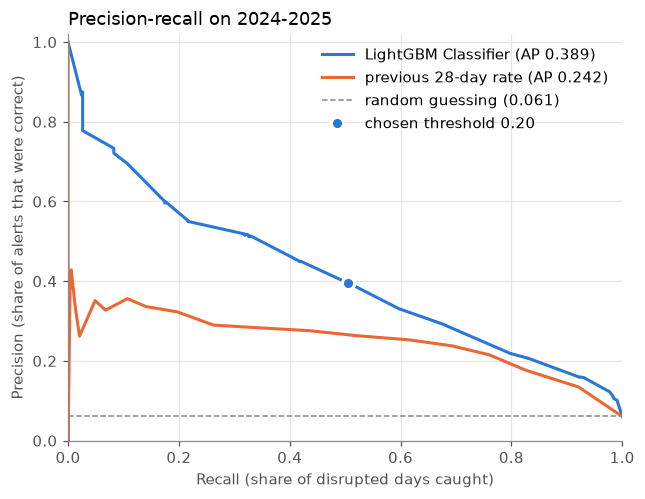

In [43]:
# 11.5 precision-recall curves on 2024-2025
from sklearn.metrics import precision_recall_curve

model_precision, model_recall, _ = precision_recall_curve(y_test, test_probability)
rolling_precision, rolling_recall, _ = precision_recall_curve(y_test, test_rolling)

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.plot(model_recall, model_precision, color=MODEL_COLOR, linewidth=2,
        label=f"LightGBM Classifier (AP {average_precision_score(y_test, test_probability):.3f})")
ax.plot(rolling_recall, rolling_precision, color=SECOND_COLOR, linewidth=2,
        label=f"previous 28-day rate (AP {average_precision_score(y_test, test_rolling):.3f})")
ax.axhline(y_test.mean(), color=REFERENCE_COLOR, linestyle="--", linewidth=1,
           label=f"random guessing ({y_test.mean():.3f})")
ax.plot(model_threshold_scores["recall"], model_threshold_scores["precision"], marker="o", markersize=8,
        color=MODEL_COLOR, markeredgecolor="white", markeredgewidth=2, linestyle="none",
        label=f"chosen threshold {alert_threshold:.2f}")
ax.set_xlabel("Recall (share of disrupted days caught)")
ax.set_ylabel("Precision (share of alerts that were correct)")
ax.set_title("Precision-recall on 2024-2025", loc="left")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, loc="upper right")
plt.show()

LightGBM's curve lies above the benchmark at every recall level. It consists of straight segments because isotonic calibration leaves only a few dozen distinct probabilities. The chosen threshold corresponds to about 50% recall and 39% precision.

In [44]:
# 11.6 does performance hold in both test years?
year_rows = []
for year in [2024, 2025]:
    in_year = test_years == year
    year_rows.append({
        "year": year,
        "rows": int(in_year.sum()),
        "disrupted_days": int(y_test[in_year].sum()),
        "model_AP": average_precision_score(y_test[in_year], test_probability[in_year]),
        "benchmark_28d_AP": average_precision_score(y_test[in_year], test_rolling[in_year]),
        "model_recall": recall_score(y_test[in_year], test_alerts[in_year], zero_division=0),
        "model_precision": precision_score(y_test[in_year], test_alerts[in_year], zero_division=0),
    })
pd.DataFrame(year_rows).round(3)

,year,rows,disrupted_days,model_AP,benchmark_28d_AP,model_recall,model_precision
0,2024,4391,278,0.377,0.245,0.50,0.397
1,2025,4380,255,0.404,0.239,0.51,0.392


AP was 0.377 in 2024 and 0.404 in 2025, with recall about 0.50 and precision 0.39–0.40 in both years.

## 12. Results by airport

Airports with fewer than 20 disrupted test days are flagged as unstable. Undefined metrics are left as `NaN`. Consecutive days are correlated, so the effective sample size is smaller than the row count.

In [45]:
# 12.1 one row per airport for 2024-2025
test_results = test_days[["airport_icao", "airport_name", "date", "year"]].copy()
test_results["actual"] = y_test.to_numpy()
test_results["probability"] = test_probability
test_results["alert"] = test_alerts
test_results["benchmark_28d"] = test_rolling

airport_rows = []
for airport, group in test_results.groupby("airport_icao"):
    disrupted_days = int(group["actual"].sum())
    alerts = int(group["alert"].sum())
    row = {
        "airport": airport,
        "name": group["airport_name"].iloc[0],
        "days": len(group),
        "disrupted_days": disrupted_days,
        "alerts": alerts,
        "few_events": disrupted_days < 20,
        "model_AP": np.nan,
        "benchmark_28d_AP": np.nan,
        "recall": np.nan,
        "precision": np.nan,
    }
    if 0 < disrupted_days < len(group):
        row["model_AP"] = average_precision_score(group["actual"], group["probability"])
        row["benchmark_28d_AP"] = average_precision_score(group["actual"], group["benchmark_28d"])
        row["recall"] = recall_score(group["actual"], group["alert"])
    if alerts > 0:
        row["precision"] = precision_score(group["actual"], group["alert"])
    row["brier_score"] = brier_score_loss(group["actual"], group["probability"])
    airport_rows.append(row)

airport_metrics = pd.DataFrame(airport_rows).sort_values("disrupted_days", ascending=False)
airport_metrics.round(3)

,airport,name,days,disrupted_days,alerts,few_events,model_AP,benchmark_28d_AP,recall,precision,brier_score
1,EDDF,Frankfurt,731,198,276,False,0.626,0.304,0.722,0.518,0.148
4,EDDK,Cologne-Bonn,731,124,167,False,0.410,0.294,0.556,0.413,0.126
6,EDDM,Munich,731,85,140,False,0.299,0.202,0.506,0.307,0.097
9,EDDS,Stuttgart,731,52,28,False,0.118,0.109,0.058,0.107,0.066
8,EDDP,Leipzig-Halle,731,38,21,False,0.124,0.057,0.132,0.238,0.048
5,EDDL,Duesseldorf,731,25,37,False,0.081,0.035,0.200,0.135,0.035
3,EDDH,Hamburg,731,8,13,True,0.144,0.022,0.125,0.077,0.012
2,EDDG,Muenster-Osnabrueck,731,1,0,True,0.001,0.001,0.000,NaN,0.001
7,EDDN,Nuremberg,731,1,0,True,0.001,0.001,0.000,NaN,0.001
11,EDDW,Bremen,731,1,0,True,0.001,0.001,0.000,NaN,0.001


- Frankfurt: AP 0.626, recall 0.72, precision 0.52, the best airport by far.
- Cologne-Bonn and Munich: AP 0.410 and 0.299.
- Stuttgart: again only 3 of 52 disrupted days caught (recall 0.06), the same failure as the logistic regression.
- Düsseldorf: AP 0.081, barely above its test disruption rate (3.4%).
- Hamburg: AP 0.144 from only 8 events, so highly unstable.

The five quietest airports have too few or no events for AP or recall to be meaningful. Unlike the logistic regression, LightGBM raised no false alerts at any of them.

## 13. Interpretation

Gain importance (cell 13.1) is measured on the training data and tends to favour inputs with many distinct values. Permutation importance on 2023 (cell 13.2) is the same method as in notebook 03 and is the fairer comparison between the models; it is descriptive only. Tree importances do not give a direction of effect, inputs can matter only in interaction, correlated inputs share importance, and none of this implies causation.

In [46]:
# 13.1 gain importance from training (share of the total gain)
gain = final_model.booster_.feature_importance(importance_type="gain")
splits = final_model.booster_.feature_importance(importance_type="split")
gain_importance = pd.DataFrame({
    "feature": X_train.columns,
    "gain_share_percent": 100 * gain / gain.sum(),
    "times_used_in_splits": splits,
}).sort_values("gain_share_percent", ascending=False)
gain_importance.head(12).round(2)

,feature,gain_share_percent,times_used_in_splits
35,disrupted_rate_28d,18.40,43
34,delay_per_arrival_mean_28d,15.86,113
33,delay_per_arrival_mean_7d,9.41,95
28,arrivals_lag7,6.36,187
31,share_delayed15_lag1,6.16,32
24,thunder_hours,5.94,92
20,vis_min_m,4.84,142
30,delay_per_arrival_lag1,3.71,49
14,gust_max_ms,2.48,147
27,arrivals_lag1,2.13,110


History columns dominate the training gain: 28-day disruption rate (18%), 28-day mean delay (16%), 7-day mean delay (9%), arrivals a week earlier (6%) and yesterday's share delayed by more than 15 minutes (6%). The main weather inputs are thunderstorm hours (5.9%) and minimum visibility (4.8%). The airport accounts for only about 2% of the gain, as the trees can separate airports through their arrival counts.

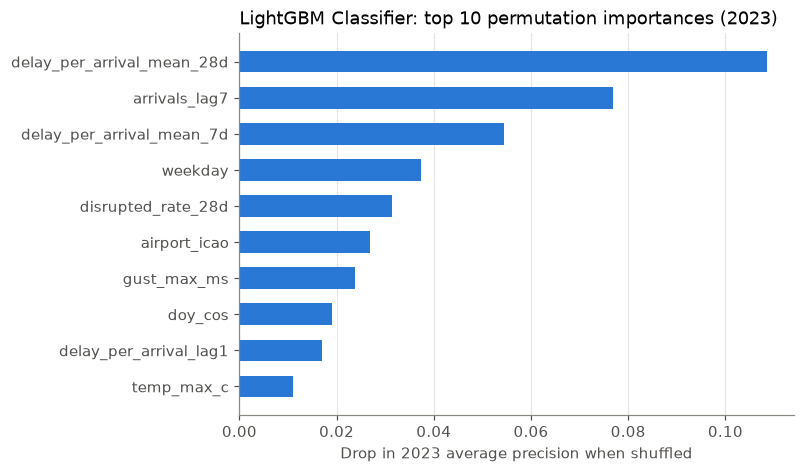

,feature,AP_drop_mean,AP_drop_std
34,delay_per_arrival_mean_28d,0.1086,0.0076
28,arrivals_lag7,0.0768,0.0085
33,delay_per_arrival_mean_7d,0.0544,0.0108
1,weekday,0.0373,0.0035
35,disrupted_rate_28d,0.0314,0.0066
0,airport_icao,0.0268,0.0043
14,gust_max_ms,0.0238,0.0048
4,doy_cos,0.0191,0.0059
30,delay_per_arrival_lag1,0.0169,0.0062
9,temp_max_c,0.0111,0.0027


In [47]:
# 13.2 permutation importance on 2023 (drop in average precision when a column is shuffled)
from sklearn.inspection import permutation_importance

permutation = permutation_importance(
    final_model, X_calibrate, y_calibrate,
    scoring="average_precision", n_repeats=5, random_state=RANDOM_SEED,
)
permutation_table = pd.DataFrame({
    "feature": X_calibrate.columns,
    "AP_drop_mean": permutation.importances_mean,
    "AP_drop_std": permutation.importances_std,
}).sort_values("AP_drop_mean", ascending=False)

top_permutation = permutation_table.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(top_permutation["feature"], top_permutation["AP_drop_mean"], color=MODEL_COLOR, height=0.6)
ax.set_xlabel("Drop in 2023 average precision when shuffled")
ax.set_title("LightGBM Classifier: top 10 permutation importances (2023)", loc="left")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
plt.show()

permutation_table.head(10).round(4)

- The largest AP drops on 2023 come from the 28-day mean delay (−0.109), arrivals a week earlier (−0.077), the 7-day mean delay (−0.054) and weekday (−0.037).
- The 28-day disruption rate tops the gain ranking but is only fifth here; it is correlated 0.87 with the 28-day mean delay, so the model can fall back on the other column. Thunderstorm hours have high training gain but are not in the 2023 top 10.
- The day-of-week pattern beyond weekend versus weekday matters for LightGBM. The logistic regression uses `is_weekend` but can only fit a linear effect of the weekday number (section 7 of notebook 03). This is one concrete pattern the tree model uses that the linear model in its current form cannot express.

In [48]:
# 13.3 how strongly do the history predictors overlap? (training years)
history_columns = [
    "delay_per_arrival_lag1", "share_delayed15_lag1", "disrupted_lag1",
    "delay_per_arrival_mean_7d", "delay_per_arrival_mean_28d", "disrupted_rate_28d",
]
X_train[history_columns].corr().round(2)

,delay_per_arrival_lag1,share_delayed15_lag1,disrupted_lag1,delay_per_arrival_mean_7d,delay_per_arrival_mean_28d,disrupted_rate_28d
delay_per_arrival_lag1,1.00,0.94,0.68,0.52,0.37,0.33
share_delayed15_lag1,0.94,1.00,0.76,0.52,0.38,0.35
disrupted_lag1,0.68,0.76,1.00,0.44,0.37,0.43
delay_per_arrival_mean_7d,0.52,0.52,0.44,1.00,0.72,0.63
delay_per_arrival_mean_28d,0.37,0.38,0.37,0.72,1.00,0.87
disrupted_rate_28d,0.33,0.35,0.43,0.63,0.87,1.00


The same correlations as in notebook 03: 0.94 between yesterday's delay per arrival and yesterday's share delayed by more than 15 minutes, and 0.87 between the 28-day mean delay and the 28-day disruption rate.

## 14. Saved outputs

Saved to `outputs/04_lightgbm_classification/`: `model.joblib` (frozen model, calibration wrapper, threshold, predictor list, airport category list, settings and library versions), `test_predictions_2024_2025.csv`, `test_metrics.csv`, `airport_metrics.csv`, `tuning_results.csv` and `calibration_results.csv`. The model is then reloaded to check that it reproduces the saved predictions.

In [49]:
# 14.1 save everything needed to reuse and check this model
import joblib

OUTPUT_DIR = PROJECT_ROOT / "outputs" / "04_lightgbm_classification"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

saved_model = {
    "model": chosen_model,
    "uncalibrated_model": final_model,
    "calibration": chosen_calibration,
    "alert_threshold": alert_threshold,
    "predictor_columns": predictor_columns,
    "airport_categories": airport_categories,
    "settings": {"num_leaves": best_num_leaves, "min_child_samples": best_min_child_samples, "trees": best_trees, "random_seed": RANDOM_SEED},
    "training_years": "2014-2021",
    "description": "LightGBM classifier; airport_icao must be a pandas Categorical with airport_categories, other inputs float64 with NaN for missing",
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
                 "scikit-learn": sklearn.__version__, "lightgbm": lgb.__version__},
}
joblib.dump(saved_model, OUTPUT_DIR / "model.joblib")

test_metrics = test_probability_metrics.merge(test_threshold_metrics, on="rule", how="left")
test_metrics.loc[test_metrics["rule"] == "LightGBM Classifier", "select_2022_AP"] = average_precision_score(y_select, final_select_probability)
test_metrics.loc[test_metrics["rule"] == "LightGBM Classifier", "calibration"] = chosen_calibration

test_results.to_csv(OUTPUT_DIR / "test_predictions_2024_2025.csv", index=False)
test_metrics.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
airport_metrics.to_csv(OUTPUT_DIR / "airport_metrics.csv", index=False)
tuning_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)
calibration_results.to_csv(OUTPUT_DIR / "calibration_results.csv", index=False)

for saved_file in sorted(OUTPUT_DIR.iterdir()):
    print(saved_file.name)

airport_metrics.csv
calibration_results.csv
model.joblib
test_metrics.csv
test_predictions_2024_2025.csv
tuning_results.csv


In [50]:
# 14.2 reload the saved model and check it reproduces the saved predictions
reloaded = joblib.load(OUTPUT_DIR / "model.joblib")
reloaded_probability = reloaded["model"].predict_proba(X_test)[:, 1]
print("Reloaded model gives identical test probabilities:", np.allclose(reloaded_probability, test_probability))
print("Saved alert threshold:", reloaded["alert_threshold"])

Reloaded model gives identical test probabilities: True
Saved alert threshold: 0.2


The reloaded model reproduces the test probabilities exactly. Inputs must be built as in cell 5.3, with the airport as a category using the saved `airport_categories` list.

## Comparison with logistic regression

The next cell reads the saved results of notebook 03 (`outputs/03_logistic_regression/`), so notebook 03 must be run first. It first checks that both notebooks scored the same airport-days.

In [51]:
# 14.3 confirm both notebooks scored the same rows, then build the comparison table
logistic_folder = PROJECT_ROOT / "outputs" / "03_logistic_regression"
logistic_predictions = pd.read_csv(logistic_folder / "test_predictions_2024_2025.csv")
logistic_metrics = pd.read_csv(logistic_folder / "test_metrics.csv")

same_rows = (
    list(logistic_predictions["airport_icao"]) == list(test_results["airport_icao"])
    and list(pd.to_datetime(logistic_predictions["date"])) == list(test_results["date"])
    and list(logistic_predictions["actual"]) == list(test_results["actual"])
)
print("Both notebooks evaluated the same", len(test_results), "airport-days with the same labels:", same_rows)

is_logistic_row = logistic_metrics["rule"].str.startswith("Logistic Regression")
is_lightgbm_row = test_metrics["rule"].str.startswith("LightGBM")
comparison = pd.concat([
    logistic_metrics[is_logistic_row],
    test_metrics[is_lightgbm_row],
    test_metrics[~is_lightgbm_row],
])
comparison_columns = [
    "rule", "select_2022_AP", "average_precision", "roc_auc", "brier_score",
    "calibration", "threshold", "alerts", "precision", "recall", "f1",
]
classification_comparison = comparison[comparison_columns].reset_index(drop=True)
classification_comparison.to_csv(OUTPUT_DIR / "classification_comparison.csv", index=False)
classification_comparison.round(4)

Both notebooks evaluated the same 8771 airport-days with the same labels: True


,rule,select_2022_AP,average_precision,roc_auc,brier_score,calibration,threshold,alerts,precision,recall,f1
0,Logistic Regression,0.4652,0.3759,0.8885,0.0460,sigmoid,0.20,875.0,0.3440,0.5647,0.4276
1,Logistic Regression before calibration (refere...,NaN,0.3759,0.8885,0.0464,NaN,NaN,NaN,NaN,NaN,NaN
2,LightGBM Classifier,0.4949,0.3887,0.8954,0.0447,isotonic,0.20,682.0,0.3944,0.5047,0.4428
3,LightGBM Classifier before calibration (refere...,NaN,0.4144,0.8976,0.0446,NaN,NaN,NaN,NaN,NaN,NaN
4,previous 28-day rate,NaN,0.2422,0.8484,0.0501,NaN,0.15,1297.0,0.2529,0.6154,0.3585
5,constant training rate,NaN,0.0608,0.5000,0.0571,NaN,NaN,NaN,NaN,NaN,NaN


Both notebooks scored the same 8,771 airport-days with the same labels.

In [52]:
# 14.4 the two models by airport, side by side (average precision on 2024-2025)
logistic_airports = pd.read_csv(logistic_folder / "airport_metrics.csv")
airport_comparison = logistic_airports[["airport", "name", "days", "disrupted_days", "model_AP", "recall"]].rename(
    columns={"model_AP": "logistic_AP", "recall": "logistic_recall"}
)
airport_comparison = airport_comparison.merge(
    airport_metrics[["airport", "model_AP", "recall", "benchmark_28d_AP"]].rename(
        columns={"model_AP": "lightgbm_AP", "recall": "lightgbm_recall"}
    ),
    on="airport",
)
airport_comparison["AP_difference_lgbm_minus_logistic"] = airport_comparison["lightgbm_AP"] - airport_comparison["logistic_AP"]
airport_comparison.to_csv(OUTPUT_DIR / "airport_comparison.csv", index=False)
airport_comparison.round(3)

,airport,name,days,disrupted_days,logistic_AP,logistic_recall,lightgbm_AP,lightgbm_recall,benchmark_28d_AP,AP_difference_lgbm_minus_logistic
0,EDDF,Frankfurt,731,198,0.548,0.793,0.626,0.722,0.304,0.078
1,EDDK,Cologne-Bonn,731,124,0.433,0.637,0.410,0.556,0.294,-0.023
2,EDDM,Munich,731,85,0.330,0.553,0.299,0.506,0.202,-0.031
3,EDDS,Stuttgart,731,52,0.174,0.058,0.118,0.058,0.109,-0.056
4,EDDP,Leipzig-Halle,731,38,0.156,0.132,0.124,0.132,0.057,-0.031
5,EDDL,Duesseldorf,731,25,0.165,0.320,0.081,0.200,0.035,-0.083
6,EDDH,Hamburg,731,8,0.037,0.250,0.144,0.125,0.022,0.106
7,EDDG,Muenster-Osnabrueck,731,1,0.004,0.000,0.001,0.000,0.001,-0.002
8,EDDN,Nuremberg,731,1,0.005,0.000,0.001,0.000,0.001,-0.003
9,EDDW,Bremen,731,1,0.002,0.000,0.001,0.000,0.001,-0.001


Among the seven airports with at least 8 disrupted test days, LightGBM has the higher AP only at Frankfurt (+0.078) and Hamburg (+0.106, from 8 events). The logistic regression is ahead at Cologne-Bonn, Munich, Stuttgart, Leipzig-Halle and Düsseldorf. LightGBM's small overall advantage comes mainly from Frankfurt, which accounts for 198 of the 533 test events. Pooled AP also rewards ranking airports against each other, which is partly a different skill from ranking days within one airport.

## Summary

| Test 2024–2025 | Logistic regression | LightGBM |
|---|---|---|
| Average precision | 0.376 | 0.389 |
| Brier score | 0.0460 | 0.0447 |
| Alerts at threshold 0.20 | 875 | 682 |
| Precision / recall | 0.344 / 0.565 | 0.394 / 0.505 |
| F1 | 0.428 | 0.443 |

- Both models clearly beat the 28-day benchmark (AP 0.242, Brier 0.0501, F1 0.358).
- LightGBM is ahead overall by 0.013 AP. This is about the size of the year-to-year variation seen in tuning, and no significance test was run; a block bootstrap over weeks or months would be the appropriate next step, since airport-days are not independent.
- The logistic regression has the higher AP at five of the seven airports with enough events; LightGBM's advantage comes mainly from Frankfurt.
- At the same threshold LightGBM raises fewer alerts, misses more disruptions and produces fewer false alarms.
- Sigmoid calibration helped the logistic regression on both 2023 and 2024–2025. Isotonic calibration for LightGBM won on 2023 by 0.0006 Brier but reduced test AP from 0.414 to 0.389 without improving the Brier score.
- The additional complexity of LightGBM gives only a modest gain. It captures non-linear patterns such as weekday effects and starts out better calibrated, while the logistic regression is nearly as good overall, better at most individual airports and easier to explain.

Limitations for both models:
- Same-day observed weather is used as a perfect forecast, so real day-ahead performance would probably be lower.
- 2024–2025 was inspected in earlier project work.
- Several airports have almost no disrupted days, so their results cannot be assessed.
- The COVID years are part of the training data.
- Important drivers of ATFM delay are not in the data: ATC staffing, strikes, capacity regulations and the hourly timing of storms.
- The 2% definition of a disrupted day is a project choice.